In [3]:
%matplotlib inline

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

with open('../data/data.json') as f:
    data = json.load(f)

list_of_keys = []

for element in data:
    for key in element.keys():
        if type(element[key]) != dict and key not in list_of_keys:
            list_of_keys.append(key)
        elif type(element[key]) == dict:
            for subkey in element[key].keys():
                if type(element[key][subkey]) != dict and f"{key}%%{subkey}" not in list_of_keys:
                    list_of_keys.append(f"{key}%%{subkey}")
                elif type(element[key][subkey]) == dict:
                    print(key,subkey,element[key][subkey])

In [4]:
df_source = {key.replace('%%', '_') : [] for key in list_of_keys}

for element in data:
    keys = element.keys()
    for key in list_of_keys:
        if '%%' not in key:
            if key in keys:
                df_source[key].append(element[key])
            else:
                df_source[key].append(None)
        else:
            new_key, sub_key = key.split('%%')
            if new_key in keys:
                sub_keys = element[new_key].keys()
                if sub_key in sub_keys:
                    df_source[key.replace('%%', '_')].append(element[new_key][sub_key])
                else:
                    df_source[key.replace('%%', '_')].append(None)
            else:
                df_source[key.replace('%%', '_')].append(None)

df = pd.DataFrame(df_source) 

In [5]:
df.head()

,id,personal_first_name,personal_last_name,personal_email,personal_country,personal_age,personal_gender,personal_marital_status,company_name,company_num_employees,...,job_department,job_join_date,job_position_level,job_performance_score,job_last_promotion_date,job_work_hours_per_week,experience_experience_years,experience_has_certifications,experience_education_level,experience_projects_completed
0,0,Лин,Василькова,линвасилькова@apple.ru,Russia,27,F,Married,Apple,154000.0,...,Marketing,2023-07-12,Junior,3.0,2023-07-23,28.0,1.0,False,PhD,17.0
1,1,Gina,Schober,gina.schober@facebook.de,Germany,59,F,Divorced,Facebook,86482.0,...,Sales,2014-03-01,Mid,2.0,None,42.0,24.0,True,Bachelor's,23.0
2,2,Christèle,Lcq,christèlelcq@amazon.fr,France,54,F,Divorced,Amazon,1298000.0,...,HR,1992-02-29,Mid,5.0,1992-03-25,48.0,33.0,True,High School,19.0
3,3,Angeliika,Piela,angeliika.piela@apple.pl,Poland,28,F,Divorced,Apple,154000.0,...,Support,2022-09-02,Senior,5.0,2022-09-16,60.0,1.0,True,High School,50.0
4,4,Melikee,Karakılıç,,Turkey,39,F,Divorced,Microsoft,181000.0,...,HR,2013-11-13,Senior,3.0,2013-11-14,31.0,13.0,False,High School,27.0


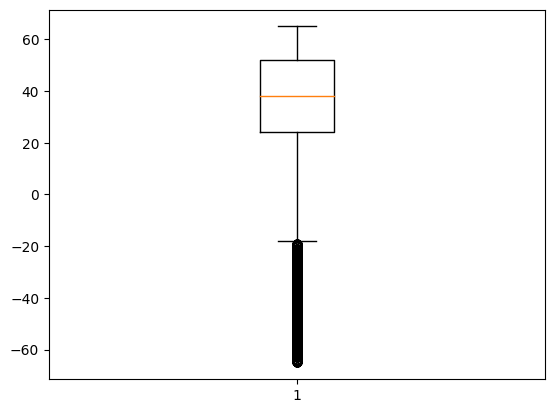

In [6]:
plt.boxplot(df["personal_age"])
plt.show()

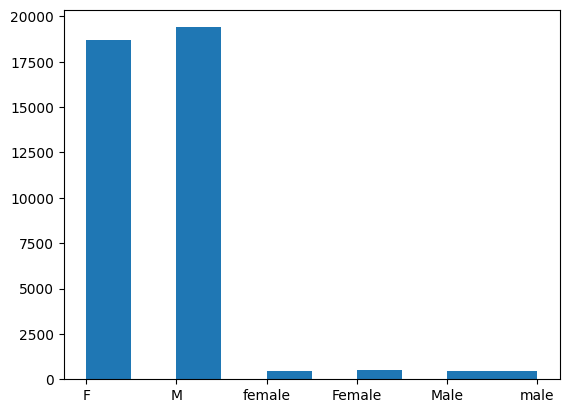

In [7]:
plt.hist(df["personal_gender"])
plt.show()

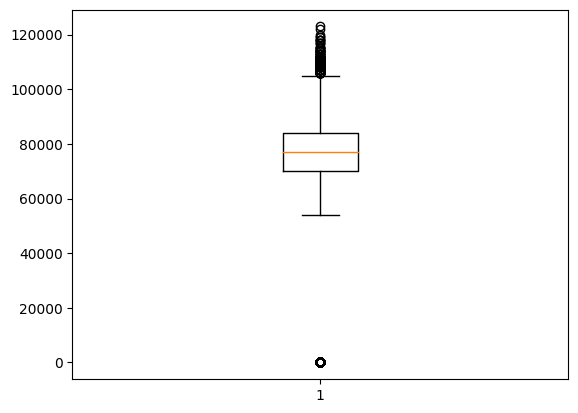

In [8]:
plt.boxplot(df[~df["job_salary"].isna()]["job_salary"])
plt.show()

In [9]:
for column in df.columns:
    print(column)

id
personal_first_name
personal_last_name
personal_email
personal_country
personal_age
personal_gender
personal_marital_status
company_name
company_num_employees
company_benefits
company_main_area_of_expertise
company_headquarters
job_salary
job_department
job_join_date
job_position_level
job_performance_score
job_last_promotion_date
job_work_hours_per_week
experience_experience_years
experience_has_certifications
experience_education_level
experience_projects_completed


In [10]:
for column in df.columns:
    if df.dtypes[column] == np.dtype('object'):
        print(column, df[column].nunique())

personal_first_name 30109
personal_last_name 27836
personal_email 33944
personal_country 36
personal_gender 6
personal_marital_status 4
company_name 5
company_benefits 5
company_main_area_of_expertise 5
company_headquarters 5
job_department 6
job_join_date 9809
job_position_level 3
job_last_promotion_date 8308
experience_has_certifications 2
experience_education_level 5


In [11]:
for column in df.columns:
    if df.dtypes[column] == np.dtype('object') and df[column].nunique() < 37:
        print(f'{column.upper()} unique values:\n')
        for element in df[column].unique():
            print(f'"{element}"')
        print('\n\n')

PERSONAL_COUNTRY unique values:

"Russia"
"Germany"
"France"
"Poland"
"Turkey"
"Bulgaria"
"United Kingdom"
"Italy"
"Switzerland"
"Portugal"
"Czech Republic"
"Netherlands"
"Sweden"
"Estonia"
"Spain"
"Georgia"
"Austria"
"Ireland"
"Denmark"
"Croatia"
"Cyprus"
"Kazakhstan"
"Norway"
"Azerbaijan"
"Finland"
"Belgium"
"Moldova"
"Hungary"
"Greece"
"Slovenia"
"Serbia"
"Albania"
"Lithuania"
"Malta"
"Iceland"
"Luxembourg"



PERSONAL_GENDER unique values:

"F"
"M"
"female"
"Female"
"Male"
"male"



PERSONAL_MARITAL_STATUS unique values:

"Married"
"Divorced"
"Single"
""
"None"



COMPANY_NAME unique values:

"Apple"
"Facebook"
"Amazon"
"Microsoft"
"Google"
"None"



COMPANY_BENEFITS unique values:

"Health insurance, stock options, employee discounts, paid time off, on-site fitness centers"
"Health insurance, free meals, transportation reimbursement, wellness programs, stock options"
"Health insurance, 401(k) plan, stock options, employee discounts, paid time off"
"Health insurance, 401(k) plan, s

In [12]:
df['personal_gender'] = df['personal_gender'].replace({'female': 'F', 'Female': 'F', 'male': 'M', 'Male': 'M'})
df['personal_gender'].unique()

array(['F', 'M'], dtype=object)

In [13]:
df.isna().sum()

id                                   0
personal_first_name                  0
personal_last_name                   0
personal_email                       0
personal_country                     0
personal_age                         0
personal_gender                      0
personal_marital_status           1632
company_name                      1632
company_num_employees             1632
company_benefits                  1632
company_main_area_of_expertise    1632
company_headquarters              1632
job_salary                        1632
job_department                    1632
job_join_date                     1632
job_position_level                1632
job_performance_score             1632
job_last_promotion_date           3470
job_work_hours_per_week           1632
experience_experience_years       1632
experience_has_certifications     1632
experience_education_level           0
experience_projects_completed     1632
dtype: int64

In [14]:
df[df['personal_marital_status'].isna()].isna().sum()

id                                   0
personal_first_name                  0
personal_last_name                   0
personal_email                       0
personal_country                     0
personal_age                         0
personal_gender                      0
personal_marital_status           1632
company_name                      1632
company_num_employees             1632
company_benefits                  1632
company_main_area_of_expertise    1632
company_headquarters              1632
job_salary                        1632
job_department                    1632
job_join_date                     1632
job_position_level                1632
job_performance_score             1632
job_last_promotion_date           1632
job_work_hours_per_week           1632
experience_experience_years       1632
experience_has_certifications     1632
experience_education_level           0
experience_projects_completed     1632
dtype: int64

In [15]:
df[df['personal_marital_status'].isna()]['personal_age'].unique()

array([ 16,  17,   0, -17, -16])

In [16]:
df.loc[df['personal_age'] < 0, 'personal_age'] = -df.loc[df['personal_age'] < 0, 'personal_age']
df['personal_age'].unique()

array([27, 59, 54, 28, 39, 23, 36, 43, 20, 22, 48, 31, 19, 45, 42, 30, 52,
       57, 26, 38, 47, 44, 65, 40, 55, 37, 21, 35, 53, 60, 62, 46, 58, 63,
       33, 51,  0, 24, 16, 17, 64, 18, 50, 29, 34, 41, 25, 32, 61, 56, 49])

In [17]:
avg_age_child = df[(df['personal_age'] <= 17) & (df['personal_age'] > 0)]['personal_age'].mean()
avg_age_adult = df[(df['personal_age'] >= 18)]['personal_age'].mean()
print(avg_age_child, avg_age_adult)

16.497072218607677 41.436421882700834


In [18]:
df.loc[(df['personal_marital_status'].isna()) & (df['personal_age'] == 0), 'personal_age'] = avg_age_child
df.loc[df['personal_age'] == 0, 'personal_age'] = avg_age_adult

/tmp/ipykernel_11086/1387332268.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '16.497072218607677' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[(df['personal_marital_status'].isna()) & (df['personal_age'] == 0), 'personal_age'] = avg_age_child


In [19]:
df['personal_age'].unique()

array([27.        , 59.        , 54.        , 28.        , 39.        ,
       23.        , 36.        , 43.        , 20.        , 22.        ,
       48.        , 31.        , 19.        , 45.        , 42.        ,
       30.        , 52.        , 57.        , 26.        , 38.        ,
       47.        , 44.        , 65.        , 40.        , 55.        ,
       37.        , 21.        , 35.        , 53.        , 60.        ,
       62.        , 46.        , 58.        , 63.        , 33.        ,
       51.        , 41.43642188, 24.        , 16.        , 17.        ,
       64.        , 18.        , 50.        , 16.49707222, 29.        ,
       34.        , 41.        , 25.        , 32.        , 61.        ,
       56.        , 49.        ])

In [20]:
df[df['personal_age'] < 18]['personal_marital_status'].unique()

array([None], dtype=object)

In [21]:
df.loc[df['personal_age'] < 18, 'personal_marital_status'] = "Single"

In [22]:
df['personal_marital_status'].unique()

array(['Married', 'Divorced', 'Single', ''], dtype=object)

In [23]:
pmsm = df[df['personal_age'] >= 18]['personal_marital_status'].mode()[0]
df['personal_marital_status'] = df['personal_marital_status'].replace({'': 'Single'})

In [24]:
df['personal_marital_status'].unique()

array(['Married', 'Divorced', 'Single'], dtype=object)

In [25]:
print(df[df['personal_age'] < 18]['experience_education_level'].unique())

print(df[df['experience_education_level'] == '']['personal_age'].unique())

['High School' '']
[63.         48.         25.         18.         36.         41.43642188
 22.         37.         16.         43.         21.         24.
 23.         20.         52.         31.         59.         34.
 29.         39.         54.         56.         60.         64.
 19.         46.         45.         51.         50.         42.
 61.         26.         49.         57.         30.         40.
 65.         17.         28.         38.         47.         62.
 35.         55.         32.         33.         44.         27.
 16.49707222 58.         53.         41.        ]


In [26]:
eelm = df[(df['experience_education_level'] != '') & (df['personal_age'] >= 18)]['experience_education_level'].mode()[0]
df.loc[df['personal_age'] < 18, 'experience_education_level'] = 'High School'
df.loc[(df['personal_age'] >= 18) & (df['experience_education_level'] == ''), 'experience_education_level'] = eelm

In [27]:
eelm

"Bachelor's"

In [28]:
print(df['experience_education_level'].unique())

['PhD' "Bachelor's" 'High School' "Master's"]


In [29]:
len(df.index)

40000

In [30]:
df_na = df.dropna()

In [31]:
len(df_na.index)

36530